# Unit 3, Exercise 4: polynomial regression

The module's cells are kept as they were. Everything under **My changes** is mine.

*The comments at the end of the module's own code lines are mine, added to explain what each line does. The module's original comments are unchanged.*

18 cars passing a certain tollboth at different time of the day (x) with different speed (y)

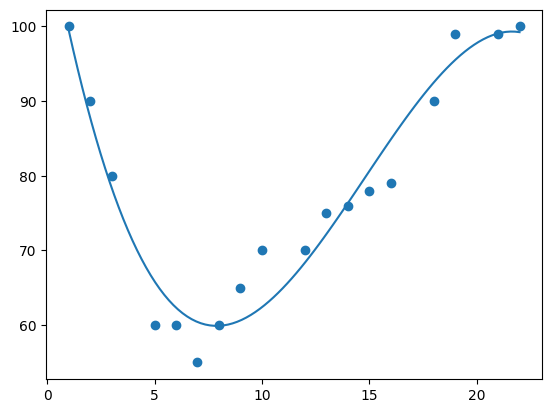

In [1]:
import numpy                                        # arrays and maths
import matplotlib.pyplot as plt                     # plotting

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]  # hour of the day a car passed
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]  # its speed

#NumPy has a method that lets us make a polynomial model
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))      # fit a degree 3 curve and turn it into a function

#specify how the line will display, we start at position 1, and end at position 22
myline = numpy.linspace(1, 22, 100)                 # 100 evenly spaced x values to draw the curve through

plt.scatter(x, y)                                   # the real data points
plt.plot(myline, mymodel(myline))                   # the fitted curve on top
plt.show()                                          # draw the plot

It is important to know how well the relationship between the values of the x- and y-axis is, if there are no relationship the polynomial regression can not be used to predict anything.

The relationship is measured with a value called the r-squared.

The r-squared value ranges from 0 to 1, where 0 means no relationship, and 1 means 100% related

In [2]:
import numpy                                        # arrays and maths
from sklearn.metrics import r2_score                # R²: share of the variation the model explains

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]  # hour of the day a car passed
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]  # its speed

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))      # fit a degree 3 curve and turn it into a function

print(r2_score(y, mymodel(x)))                      # how well the curve fits, from 0 (no fit) to 1 (perfect)

0.9432150416451026


## Predict Future Values

Let us try to predict the speed of a car that passes the tollbooth at around 17 P.M

In [3]:
import numpy                                        # arrays and maths
from sklearn.metrics import r2_score                # R²: share of the variation the model explains

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]  # hour of the day a car passed
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]  # its speed

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))      # fit a degree 3 curve and turn it into a function

speed = mymodel(17)                                 # predict the speed of a car passing at 17:00
print(speed)                                        # show the prediction

88.87331269698001


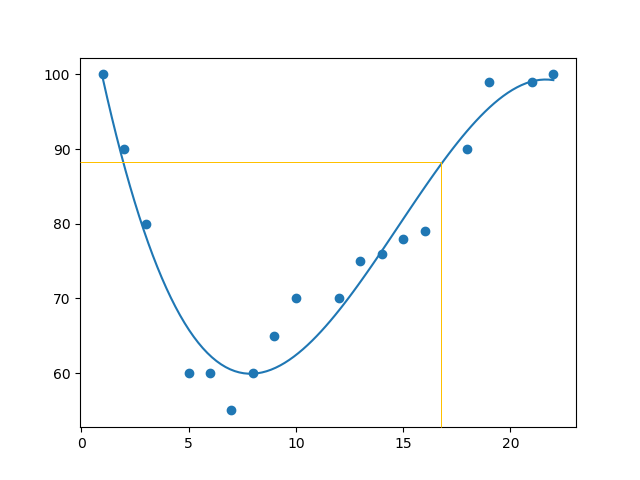

## My changes

### 1. Raise the degree: training fit vs unseen points

In [4]:
import numpy as np                                   # numpy: arrays and polynomial fitting
import matplotlib.pyplot as plt                      # plotting
from sklearn.metrics import r2_score                 # R² score

x = np.array([1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22])          # the module's hours of the day
y = np.array([100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100])  # the module's speeds

print(f"{'degree':>6} | {'R² on training points':>21} | {'avg error on left-out point':>26} | {'speed at 17:00':>14}")  # table header
for deg in range(1, 10):                             # try every polynomial degree from 1 (a straight line) to 9
    model = np.poly1d(np.polyfit(x, y, deg))         # fit a curve of this degree to all 18 points
    # Leave-one-out: refit without each point in turn, then measure how far off it is on the point it didn't see
    errs = [abs(y[i] - np.poly1d(np.polyfit(np.delete(x, i), np.delete(y, i), deg))(x[i])) for i in range(len(x))]  # error on each left-out point
    # training R², average unseen error, and the prediction the module asked for (hour 17)
    print(f"{deg:>6} | {r2_score(y, model(x)):>21.3f} | {np.mean(errs):>26.1f} | {model(17):>14.1f}")  # training R², unseen error, and the prediction at hour 17

degree | R² on training points | avg error on left-out point | speed at 17:00
     1 |                 0.182 |                       13.2 |           83.9
     2 |                 0.760 |                        7.9 |           81.2
     3 |                 0.943 |                        3.4 |           88.9
     4 |                 0.954 |                        3.7 |           87.2
     5 |                 0.957 |                        4.5 |           87.1
     6 |                 0.980 |                        4.0 |           84.3
     7 |                 0.987 |                        4.6 |           85.7
     8 |                 0.990 |                        4.1 |           85.4
     9 |                 0.990 |                        9.2 |           85.3


### 2. What each curve does just past the data

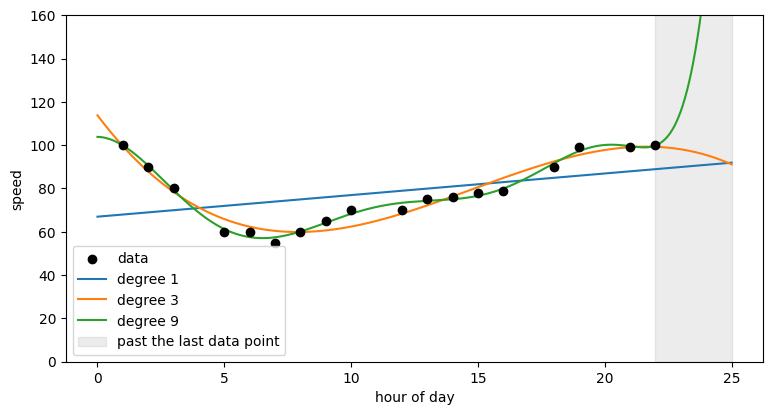

degree 3: predicted speed at hour 24 = 95
degree 9: predicted speed at hour 24 = 181


In [5]:
line = np.linspace(0, 25, 300)                       # x values from 0 to 25, a little beyond the data (which ends at 22)
plt.figure(figsize=(9, 4.5))                         # one wide plot
plt.scatter(x, y, color="black", zorder=3, label="data")   # the real points, drawn on top
for deg in [1, 3, 9]:                                # an underfit, a good fit and an overfit curve
    plt.plot(line, np.poly1d(np.polyfit(x, y, deg))(line), label=f"degree {deg}")  # draw this degree's curve
plt.axvspan(22, 25, color="grey", alpha=0.15, label="past the last data point")   # shade the region with no data
plt.ylim(0, 160); plt.xlabel("hour of day"); plt.ylabel("speed"); plt.legend(); plt.show()   # labels and draw
for deg in [3, 9]:                                   # print the two predictions two hours past the data
    print(f"degree {deg}: predicted speed at hour 24 = {np.poly1d(np.polyfit(x, y, deg))(24):.0f}")  # prediction two hours past the data

## What I took from it


- **More flexible is not more accurate.** Training R² keeps rising with the degree: 0.94 at degree 3, 0.99 at
  degree 9. But the error on a point the model hasn't seen is lowest at degree 3 (3.4) and more than doubles
  at degree 9 (9.2). The extra flexibility fits the noise in 18 points, not the pattern. That is overfitting,
  and you only see it if you test on points the model didn't train on.
- **The module's choice of degree 3 was right**, and now I can show why rather than taking it on trust.
- **Overfit models fall apart at the edges.** Just two hours past the last data point, degree 3 predicts 95,
  which is plausible. Degree 9 predicts 181. The high-degree curve shoots off as soon as it leaves the data.